In [5]:
import os

os.chdir(r"/data/home/ascisel/open_webui/iSTS-mgr")

In [10]:
from datasets import Dataset
import torch
import random

class TokenBufferDataset(Dataset):
    def __init__(self, texts, tokenizer, max_tokens=512):
        self.texts = texts
        self.max_tokens = max_tokens
        self.tokenizer = tokenizer
        self.buffer = []
        self.current_token_count = 0
        
    def __len__(self):
        return len(self.texts)  # This could be adjusted based on how you want to define the dataset size
    
    def _add_text_to_buffer(self, text):
        # Tokenize and add EOS token
        tokenized = self.tokenizer(text, return_tensors='pt')
        eos_token = self.tokenizer.eos_token_id
        
        # Add input_ids and EOS token to buffer
        self.buffer.append(tokenized['input_ids'].squeeze(0))
        self.buffer.append(torch.tensor([eos_token]))  # EOS token
        self.current_token_count += tokenized['input_ids'].size(1) + 1  # +1 for EOS token

    def _clear_buffer(self):
        full_buffer = torch.cat(self.buffer)
        leftover_tokens = full_buffer[self.max_tokens :]
        self.buffer = [leftover_tokens]  # Update buffer to hold the leftovers
        self.current_token_count = leftover_tokens.size(0)  # Update token count
        return full_buffer

    def __getitem__(self, index):
        while True:
            # Select a random text
            text = random.choice(self.texts)
            self._add_text_to_buffer(text)

            # Check if the buffer has reached the max token limit
            if self.current_token_count >= self.max_tokens:
                return self._clear_buffer()  # Return the full buffer if full

In [30]:
# from datasets import Dataset, IterableDataset
from torch.utils.data import IterableDataset, DataLoader
import torch
import random

class DatasetWrapper(IterableDataset):
    def __init__(self, dataset, tokenizer, max_tokens=20):
        self.dataset = dataset
        self.max_tokens = max_tokens
        self.tokenizer = tokenizer
        
    def __len__(self):
        return len(self.dataset)

    def __iter__(self):
        buffer = []
        random.shuffle(self.dataset)
        for text in self.dataset:
            buffer += self.tokenizer(text)["input_ids"]
            buffer += [self.tokenizer.eos_token_id]
            while len(buffer) > self.max_tokens:
                yield torch.tensor(buffer[: self.max_tokens])
                buffer = buffer[self.max_tokens :]
                

In [31]:
from torch.utils.data import DataLoader
from transformers import AutoTokenizer

In [32]:
tokenizer = AutoTokenizer.from_pretrained("EleutherAI/Pythia-410m")

/storage2/albert/envs/pythia-env/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


In [24]:
from tqdm import tqdm

In [37]:
texts = ["Your text data here.", "Another piece of text.", "More texts to choose from.", "siema co tam u ciebie balaszku"]
dataset = DatasetWrapper(texts, tokenizer, max_tokens=5)  # Example max_tokens

dataloader = DataLoader(dataset, batch_size=1)
prog = tqdm(dataloader)

for i, batch in enumerate(prog):
    # print(batch.shape)
    # print(batch)
    print(tokenizer.batch_decode(batch))

  0%|          | 0/4 [00:00<?, ?it/s]/storage2/albert/envs/pythia-env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:641: UserWarning: Length of IterableDataset <__main__.DatasetWrapper object at 0x7fae736db290> was reported to be 4(when accessing len(dataloader)), but 5 samples have been fetched. 
  warnings.warn(warn_msg)
/storage2/albert/envs/pythia-env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:641: UserWarning: Length of IterableDataset <__main__.DatasetWrapper object at 0x7fae736db290> was reported to be 4(when accessing len(dataloader)), but 6 samples have been fetched. 
  warnings.warn(warn_msg)
6it [00:00, 1751.64it/s]             

['More texts to choose from']
['.<|endoftext|>siema co']
[' tam u ciebie']
[' balaszku<|endoftext|>']
['Your text data here.']
['<|endoftext|>Another piece of text']


In [6]:
from src.data.data import get_df_from_wa

df = get_df_from_wa("/data/home/ascisel/open_webui/iSTS-mgr/Data/test_data/wa/processed_STSint.testinput.answers-students.xml")
df

,text_source,text_translation,alignment,score
0,both,Bulbs A and C,EQUI,5
1,have,are,EQUI,5
2,still,still,EQUI,5
3,bulbs a and c,Bulbs A and C,EQUI,5
4,a closed path,in closed paths,SPE1,4
...,...,...,...,...
1835,-not aligned-,The battery,NOALI,0
1836,has,does not contain,OPPO,4
1837,-not aligned-,which,NOALI,0
1838,-not aligned-,in a path,NOALI,0


In [27]:
import os
os.chdir("/data/home/ascisel/open_webui/iSTS-mgr/")

from src.prompt_modeling import create_prompt
from src.data.data import get_dataframe
from functools import partial

dataset = "headlines"

df_test_wa = get_dataframe(dataset, "test", "wa")
df_train_wa = get_dataframe(dataset, "train", "wa")

_formating_prompt = partial(create_prompt, df=df_train_wa, 
                            instruction_type="score",
                            label_description_type="detailed", 
                            task_type="score",
                            n_examples = 5)

prompts = df_test_wa.apply(_formating_prompt, axis=1)

In [17]:
df_train_wa[["text_source", "text_translation"]]

,text_source,text_translation
0,.,-not aligned-
1,-not aligned-,high up
2,-not aligned-,.
3,A cat,A black and white cat
4,standing,is
...,...,...
4800,from a bird feeder,-not aligned-
4801,hanging,-not aligned-
4802,-not aligned-,.
4803,is eating,-not aligned-


In [28]:
keys = ["text_source", "text_translation"]
rows = df_train_wa.merge(df_test_wa[keys].drop_duplicates(), on=keys, how="inner")

In [29]:
not_allowed = [".", "-not aligned-"]
rows_filtered = rows[~rows["text_source"].isin(not_allowed)]
rows_filtered

,text_source,text_translation,alignment,score,merged,both
0,dead,dies,EQUI,5,5-EQUI,5-EQUI
3,kills,kills,EQUI,5,5-EQUI,5-EQUI
4,in Pakistan,in Pakistan,EQUI,5,5-EQUI,5-EQUI
5,says,-not aligned-,NOALI,0,0-NOALI,0-NOALI
6,",",-not aligned-,NOALI,0,0-NOALI,0-NOALI
...,...,...,...,...,...,...
717,rises,rises,EQUI,5,5-EQUI,5-EQUI
718,China,-not aligned-,NOALI,0,0-NOALI,0-NOALI
719,Israel,Israel,EQUI,5,5-EQUI,5-EQUI
720,Obama,Obama,EQUI,5,5-EQUI,5-EQUI


In [ ]:

from typing import List, Dict, Any
import numpy as np
from transformers import AutoTokenizer


def token_stats(
    model_name: str,
    texts: List[str],
) -> Dict[str, Any]:
    """
    Compute token-count stats for a Hugging Face tokenizer.

    Returns:
      - mean_tokens: average tokens per string
      - min_tokens: minimum tokens among strings
      - counts: per-string token counts (list[int])
      - (also includes max/median/std, handy for debugging)
    """

    tok = AutoTokenizer.from_pretrained(model_name)

    counts = []
    for t in texts:
        # tokenize without padding/truncation; just count ids
        ids = tok(t)["input_ids"]
        counts.append(len(ids))

    arr = np.asarray(counts, dtype=np.int64)
    return {
        "model_name": model_name,
        "n_texts": len(texts),
        "mean_tokens": float(arr.mean()),
        "min_tokens": int(arr.min()),
        "max_tokens": int(arr.max()),
        "median_tokens": float(np.median(arr)),
        "std_tokens": float(arr.std(ddof=0)),
    }

In [29]:
token_stats("mistralai/Mistral-7B-Instruct-v0.3", prompts.to_list())

{'model_name': 'mistralai/Mistral-7B-Instruct-v0.3',
 'n_texts': 1840,
 'mean_tokens': 16051.116847826086,
 'min_tokens': 16047,
 'max_tokens': 16069,
 'median_tokens': 16050.0,
 'std_tokens': 3.1574513075345747}

In [6]:
import matplotlib.pyplot as plt
from pathlib import Path



plt.rcParams.update({
    "font.size": 14,         # bazowy rozmiar
    "axes.titlesize": 18,    # tytuł
    "axes.labelsize": 16,    # etykiety osi
    "xtick.labelsize": 14,   # opisy na osi X
    "ytick.labelsize": 14,   # opisy na osi Y
})
# df columns assumed: [text_col1, text_col2, "alignment", "score"]

def plot_counts(df, col, order=None, title=None, color=None, save_pdf_path=None, show=True):
    counts = df[col].value_counts(dropna=False)

    if order is not None:
        counts = counts.reindex(order, fill_value=0)

    x = counts.index.astype(str)
    y = counts.values

    plt.figure(figsize=(10, 6))
    bars = plt.bar(x, y, color=color)  # <- color choice

    # numbers above bars
    try:
        plt.bar_label(bars, padding=3)
    except Exception:
        for b in bars:
            h = b.get_height()
            plt.text(
                b.get_x() + b.get_width() / 2,
                h,
                str(int(h)),
                ha="center",
                va="bottom",
                fontsize=9,
            )
    plt.bar_label(bars, padding=3, fontsize=14)
    plt.xlabel(col)
    plt.ylabel("Liczba przykładów")
    plt.title(title or f"Counts of {col}")
    plt.tight_layout()

    # save as PDF (optional)
    if save_pdf_path is not None:
        save_pdf_path = Path(save_pdf_path)
        save_pdf_path.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_pdf_path, format="pdf", bbox_inches="tight")

    if show:
        plt.show()
    else:
        plt.close()

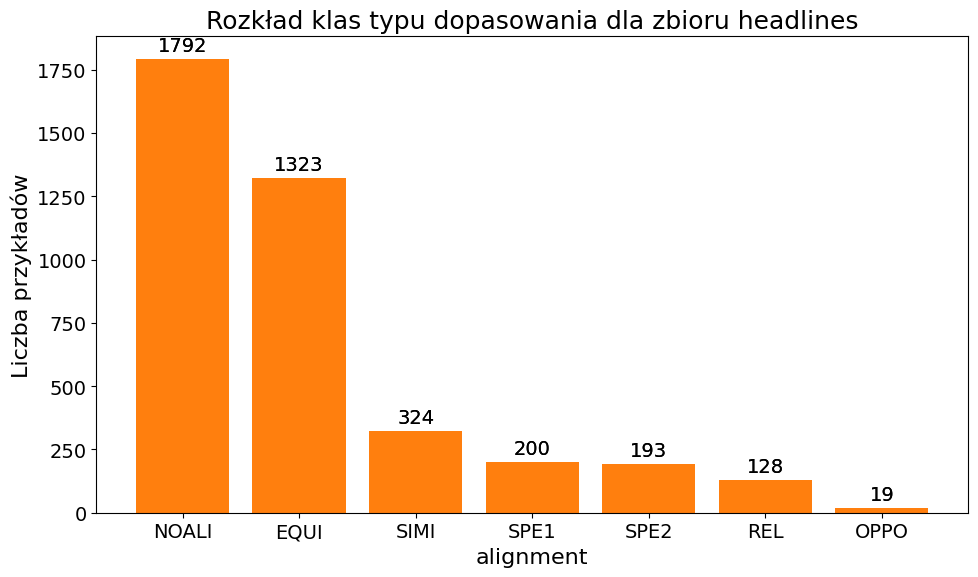

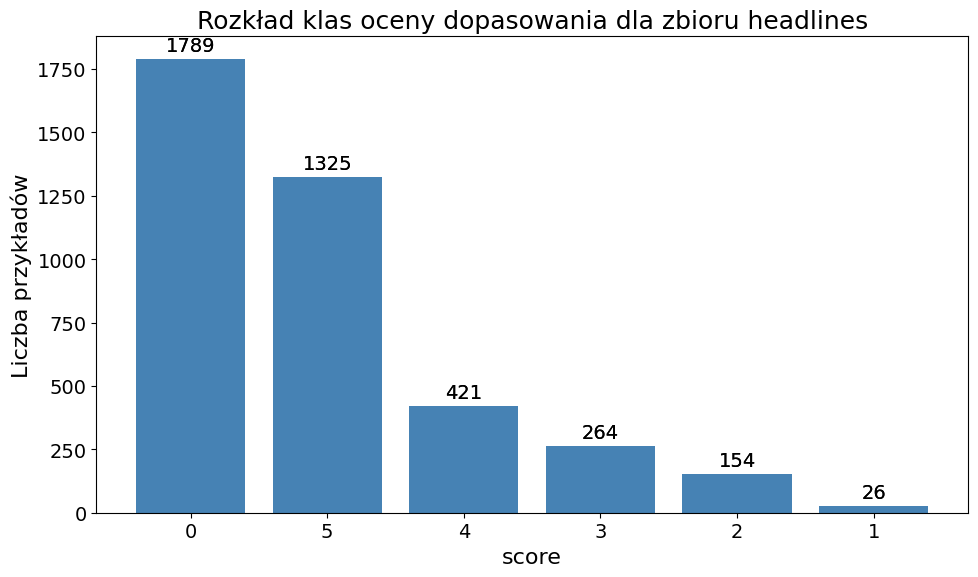

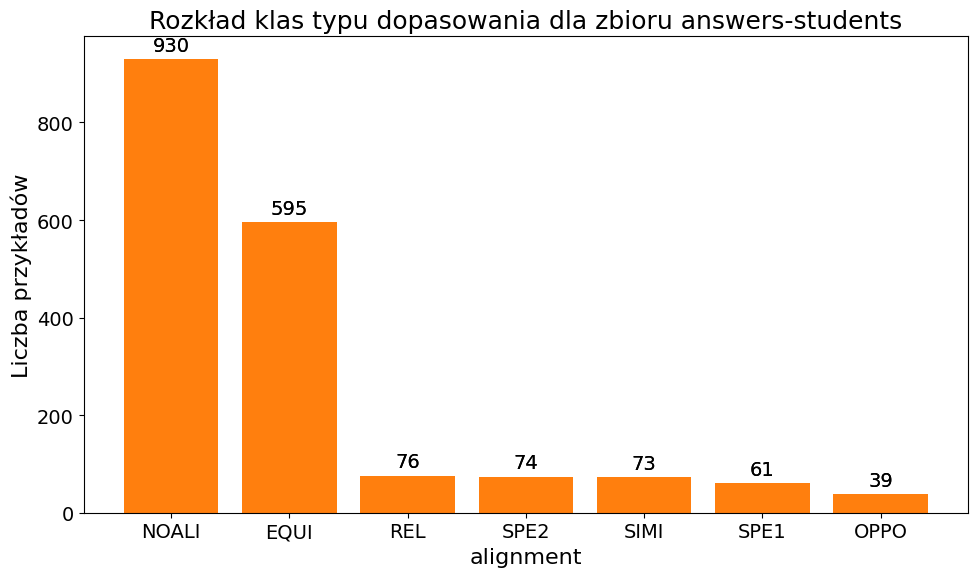

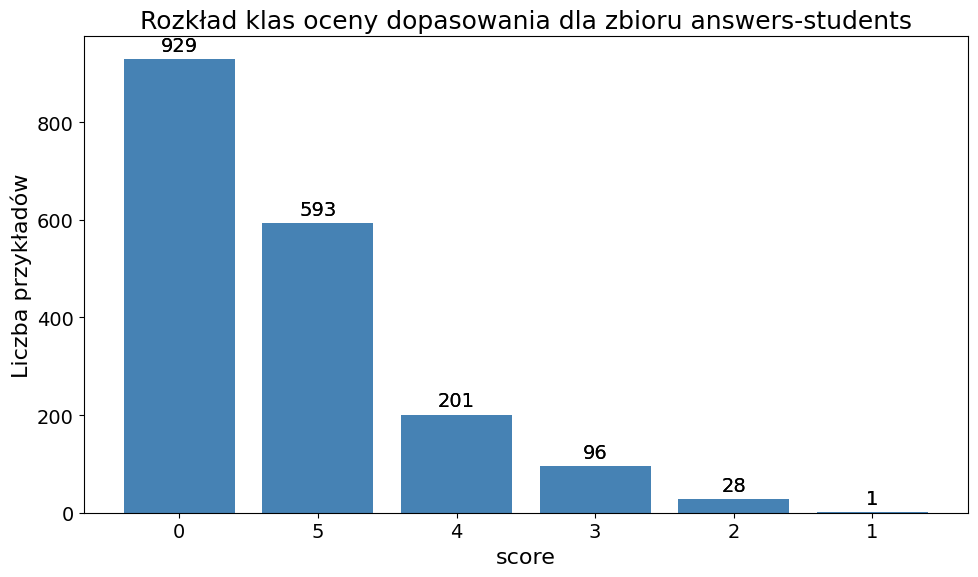

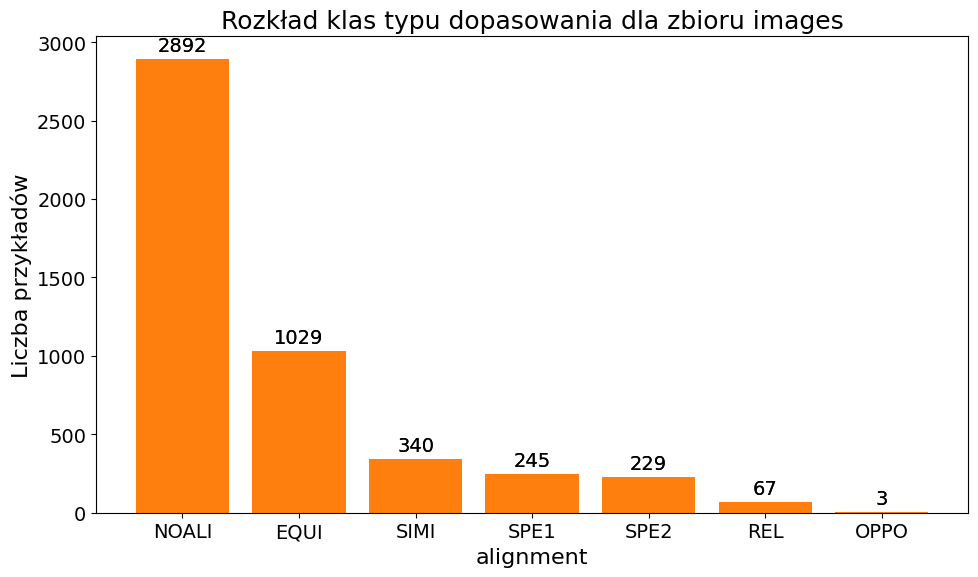

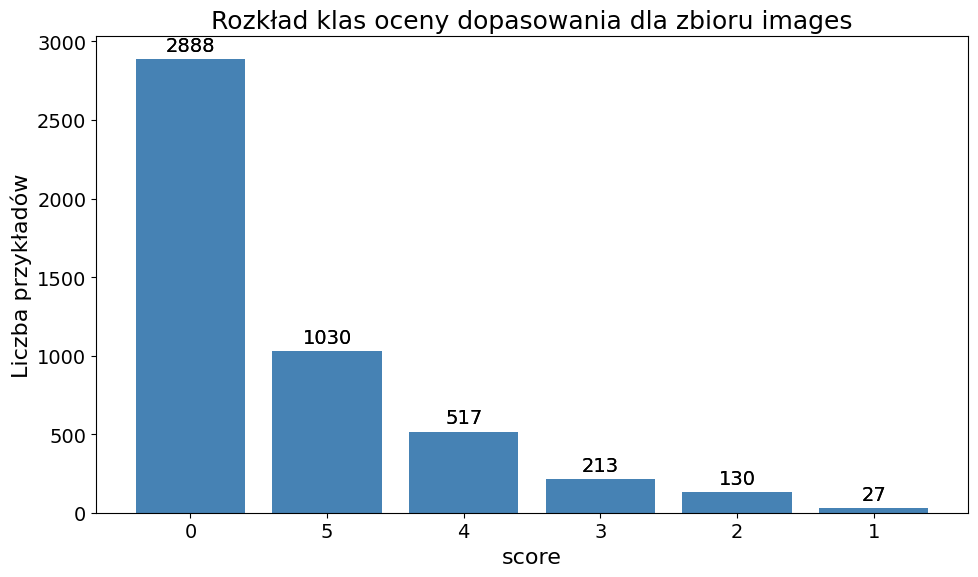

In [7]:
import os
os.chdir("/data/home/ascisel/open_webui/iSTS-mgr/")

from src.prompt_modeling import create_prompt
from src.data.data import get_dataframe
from functools import partial

datasets = ["headlines", "answers-students", "images"]

for dataset in datasets:
    df_train_wa = get_dataframe(dataset, "train", "wa")

    alignment_order = None
    plot_counts(df_train_wa, "alignment", order=alignment_order, color="#ff7f0e", title=f"Rozkład klas typu dopasowania dla zbioru {dataset}", save_pdf_path=f"/data/home/ascisel/open_webui/iSTS-mgr/results/figures/class_distribution/alignment_{dataset}.pdf")

    # 2) score (0..5) - enforce numeric order:
    score_order = None
    plot_counts(df_train_wa, "score", order=score_order, color="steelblue", title=f"Rozkład klas oceny dopasowania dla zbioru {dataset}", save_pdf_path=f"/data/home/ascisel/open_webui/iSTS-mgr/results/figures/class_distribution/score_{dataset}.pdf")


In [2]:
import pandas as pd

df_results = pd.read_csv("/data/home/ascisel/open_webui/iSTS-mgr/results_new/processed/evalF1_penalty/finetuning/both/Llama-3.1-8B-Instruct/f1_results.csv")

In [14]:
[pred for pred in df_results["preds"].tolist() if isinstance(pred, str) and "EQUI_POL" in pred]

[]

### This is for final version

In [68]:
df_penalty["run_type"].value_counts()

run_type
both      177
merged    177
paired     81
Name: count, dtype: int64

In [6]:
import pandas as pd

df_penalty = pd.read_csv("/data/home/ascisel/open_webui/iSTS-mgr/results_new/processed/evalF1_penalty/all_f1_results.csv")
df_no_penalty = pd.read_csv("/data/home/ascisel/open_webui/iSTS-mgr/results_new/processed/evalF1_no_penalty/all_f1_results.csv")

In [7]:
df_penalty["run_type"] = df_penalty["run_type"].fillna("separated").replace({"paired": "separated"})
df_no_penalty["run_type"] = df_no_penalty["run_type"].fillna("separated").replace({"paired": "separated"})

In [8]:
df_penalty[df_penalty["method"]=="finetuning"]

,timestamp,method,run_type,model,dataset,desc,idx,lr,lora_rank,run_path,gold_path,sys_path,f1_ali,f1_type,f1_score,f1_typescore,source_file
0,2026-01-25T09:53:29,finetuning,both,Llama-3.1-8B-Instruct,answers-students,simple,0,0.00001,8.0,/data/home/ascisel/open_webui/iSTS-mgr/results...,/data/home/ascisel/open_webui/iSTS-mgr/Data/te...,/data/home/ascisel/open_webui/iSTS-mgr/results...,1.0,0.6120,0.8628,0.7030,/data/home/ascisel/open_webui/iSTS-mgr/results...
1,2026-01-25T09:53:30,finetuning,both,Llama-3.1-8B-Instruct,answers-students,simple,0,0.00001,16.0,/data/home/ascisel/open_webui/iSTS-mgr/results...,/data/home/ascisel/open_webui/iSTS-mgr/Data/te...,/data/home/ascisel/open_webui/iSTS-mgr/results...,1.0,0.6074,0.8601,0.6986,/data/home/ascisel/open_webui/iSTS-mgr/results...
2,2026-01-25T09:53:30,finetuning,both,Llama-3.1-8B-Instruct,answers-students,simple,0,0.00001,32.0,/data/home/ascisel/open_webui/iSTS-mgr/results...,/data/home/ascisel/open_webui/iSTS-mgr/Data/te...,/data/home/ascisel/open_webui/iSTS-mgr/results...,1.0,0.5988,0.8664,0.6941,/data/home/ascisel/open_webui/iSTS-mgr/results...
3,2026-01-25T09:53:30,finetuning,both,Llama-3.1-8B-Instruct,answers-students,simple,0,0.00005,8.0,/data/home/ascisel/open_webui/iSTS-mgr/results...,/data/home/ascisel/open_webui/iSTS-mgr/Data/te...,/data/home/ascisel/open_webui/iSTS-mgr/results...,1.0,0.6938,0.9104,0.7699,/data/home/ascisel/open_webui/iSTS-mgr/results...
4,2026-01-25T09:53:31,finetuning,both,Llama-3.1-8B-Instruct,answers-students,simple,0,0.00005,16.0,/data/home/ascisel/open_webui/iSTS-mgr/results...,/data/home/ascisel/open_webui/iSTS-mgr/Data/te...,/data/home/ascisel/open_webui/iSTS-mgr/results...,1.0,0.6879,0.9081,0.7660,/data/home/ascisel/open_webui/iSTS-mgr/results...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
238,2026-01-25T09:52:04,finetuning,separated,Qwen2.5-7B-Instruct,images,simple,0,0.00005,16.0,/data/home/ascisel/open_webui/iSTS-mgr/results...,/data/home/ascisel/open_webui/iSTS-mgr/Data/te...,/data/home/ascisel/open_webui/iSTS-mgr/results...,1.0,0.7458,0.9513,0.8115,/data/home/ascisel/open_webui/iSTS-mgr/results...
239,2026-01-25T09:52:05,finetuning,separated,Qwen2.5-7B-Instruct,images,simple,0,0.00005,32.0,/data/home/ascisel/open_webui/iSTS-mgr/results...,/data/home/ascisel/open_webui/iSTS-mgr/Data/te...,/data/home/ascisel/open_webui/iSTS-mgr/results...,1.0,0.7558,0.9509,0.8118,/data/home/ascisel/open_webui/iSTS-mgr/results...
240,2026-01-25T09:52:05,finetuning,separated,Qwen2.5-7B-Instruct,images,simple,0,0.00010,8.0,/data/home/ascisel/open_webui/iSTS-mgr/results...,/data/home/ascisel/open_webui/iSTS-mgr/Data/te...,/data/home/ascisel/open_webui/iSTS-mgr/results...,1.0,0.7651,0.9545,0.8320,/data/home/ascisel/open_webui/iSTS-mgr/results...
241,2026-01-25T09:52:05,finetuning,separated,Qwen2.5-7B-Instruct,images,simple,0,0.00010,16.0,/data/home/ascisel/open_webui/iSTS-mgr/results...,/data/home/ascisel/open_webui/iSTS-mgr/Data/te...,/data/home/ascisel/open_webui/iSTS-mgr/results...,1.0,0.7829,0.9559,0.8232,/data/home/ascisel/open_webui/iSTS-mgr/results...


In [9]:
def prepare_df(df):
    df2 = df.copy()
    df2["lr"] = df2["lr"].astype(object).where(df2["lr"].notna(), "None")
    df2["lora_rank"] = df2["lora_rank"].astype(object).where(df2["lora_rank"].notna(), "None")


    key_cols = ["method", "run_type", "model", "desc", "idx", "lr", "lora_rank"]
    metric_cols = ["f1_ali", "f1_type", "f1_score", "f1_typescore"]

    # 1) Pivot so each dataset becomes a set of columns per metric
    wide = (
        df2.pivot_table(
            index=key_cols,
            columns="dataset",
            values=metric_cols,
            aggfunc="first",   # use 'mean' if you may have duplicates per key+dataset
        )
    )

    # 2) Flatten MultiIndex columns -> f1_type_<dataset>, f1_score_<dataset>, ...
    wide.columns = [f"{metric}_{dataset}" for metric, dataset in wide.columns]
    wide = wide.reset_index()

    # 3) Mean f1_typescore across all datasets (row-wise)
    typescore_cols = [c for c in wide.columns if c.startswith("f1_typescore_")]
    wide["mean_f1_typescore"] = wide[typescore_cols].mean(axis=1)

    # (optional) move mean column to the end (it already is, but just in case)
    mean_col = "mean_f1_typescore"
    wide = wide[[c for c in wide.columns if c != mean_col] + [mean_col]]

    return wide

results_penalty = prepare_df(df_penalty)
results_no_penalty = prepare_df(df_no_penalty)

In [10]:
import pandas as pd
import numpy as np

def create_latex_output(df, bold_max: bool = False, decimals: int = 4) -> str:
    meta_cols = ["method","run_type","model","desc","idx","lr","lora_rank"]
    datasets  = ["answers-students","headlines","images"]
    metrics   = [("f1_score","Score"), ("f1_type","Type"), ("f1_typescore","+TS")]

    # --- 1) Build MultiIndex columns (LaTeX-safe meta headers; no underscores) ---
    nice_meta = {
        "method": "Method",
        "run_type": "Run",
        "model": "Model",
        "desc": "Desc",
        "idx": "k",
        "lr": "LR",
        "lora_rank": "LoRA",
    }

    col_tuples = [("", nice_meta[c]) for c in meta_cols]
    for ds in datasets:
        for _, mname in metrics:
            col_tuples.append((ds, mname))
    col_tuples.append(("Mean", "+TS"))

    # --- 2) Pull flat columns in the same order ---
    cols_flat = [
        "method","run_type","model","desc","idx","lr","lora_rank",
        "f1_score_answers-students","f1_type_answers-students","f1_typescore_answers-students",
        "f1_score_headlines","f1_type_headlines","f1_typescore_headlines",
        "f1_score_images","f1_type_images","f1_typescore_images",
        "mean_f1_typescore",
    ]
    df_tab = df[cols_flat].copy()
    df_tab.columns = pd.MultiIndex.from_tuples(col_tuples)

    # --- 3) Format LR / LoRA / k / Model ---
    lr_num = pd.to_numeric(df_tab[("", "LR")], errors="coerce")
    df_tab[("", "LR")] = lr_num.map(
        lambda v: "None" if pd.isna(v)
        else f"{v:.0e}".replace("e-0", "e-").replace("e+0", "e+")
    )

    lora_num = pd.to_numeric(df_tab[("", "LoRA")], errors="coerce")
    df_tab[("", "LoRA")] = lora_num.map(lambda v: "None" if pd.isna(v) else str(int(v)))

    k_num = pd.to_numeric(df_tab[("", "k")], errors="coerce")
    df_tab[("", "k")] = k_num.map(lambda v: "" if pd.isna(v) else str(int(v)))

    def short_model(m: str) -> str:
        s = str(m)
        if "Qwen" in s or "qwen" in s:
            return "Qwen"
        if "Llama" in s or "llama" in s:
            return "LLaMA"
        if "Mistral" in s or "mistral" in s:
            return "Mistral"
        if "gpt" in s.lower() or "oss" in s.lower():
            return "GPT-OSS"
        return s

    df_tab[("", "Model")] = df_tab[("", "Model")].map(short_model)

    # --- 4) Ensure metric cols are numeric (so max + formatting works) ---
    metric_cols = []
    for ds in datasets:
        for _, mname in metrics:
            metric_cols.append((ds, mname))
    metric_cols.append(("Mean", "+TS"))

    for c in metric_cols:
        df_tab[c] = pd.to_numeric(df_tab[c], errors="coerce")

    # --- 5) Build per-column formatters to bold maxima ---
    max_by_col = {c: df_tab[c].max(skipna=True) for c in metric_cols}

    def make_fmt(col):
        mx = max_by_col[col]
        def fmt(v):
            if pd.isna(v):
                return ""
            s = f"{float(v):.{decimals}f}"
            if bold_max and pd.notna(mx) and np.isclose(float(v), float(mx), rtol=0.0, atol=10**(-(decimals+2))):
                return r"\textbf{" + s + "}"
            return s
        return fmt

    formatters = {c: make_fmt(c) for c in metric_cols}

    # --- 6) Export LaTeX (escape=False so \textbf works) ---
    latex_core = df_tab.to_latex(
        index=False,
        escape=False,
        longtable=True,
        multicolumn=True,
        multicolumn_format="c",
        multirow=True,
        formatters=formatters,
    )

    latex = r"""
\scriptsize
\setlength{\tabcolsep}{2pt}
\renewcommand{\arraystretch}{0.9}
\setlength{\LTleft}{0pt}
\setlength{\LTright}{0pt}
\setlength{\parindent}{0pt}
""" + latex_core

    return latex


In [11]:
print(create_latex_output(results_no_penalty, bold_max=False))


\scriptsize
\setlength{\tabcolsep}{2pt}
\renewcommand{\arraystretch}{0.9}
\setlength{\LTleft}{0pt}
\setlength{\LTright}{0pt}
\setlength{\parindent}{0pt}
\begin{longtable}{lllllllrrrrrrrrrr}
\toprule
\multicolumn{7}{c}{} & \multicolumn{3}{c}{answers-students} & \multicolumn{3}{c}{headlines} & \multicolumn{3}{c}{images} & Mean \\
Method & Run & Model & Desc & k & LR & LoRA & Score & Type & +TS & Score & Type & +TS & Score & Type & +TS & +TS \\
\midrule
\endfirsthead
\toprule
\multicolumn{7}{c}{} & \multicolumn{3}{c}{answers-students} & \multicolumn{3}{c}{headlines} & \multicolumn{3}{c}{images} & Mean \\
Method & Run & Model & Desc & k & LR & LoRA & Score & Type & +TS & Score & Type & +TS & Score & Type & +TS & +TS \\
\midrule
\endhead
\midrule
\multicolumn{17}{r}{Continued on next page} \\
\midrule
\endfoot
\bottomrule
\endlastfoot
finetuning & both & LLaMA & simple & 0 & 1e-5 & 8 & 0.8628 & 0.6120 & 0.6103 & 0.9078 & 0.5781 & 0.5697 & 0.9223 & 0.5653 & 0.5567 & 0.5789 \\
finetuning & b

In [40]:
import pandas as pd
import numpy as np
import re

def create_latex_output2(
    df: pd.DataFrame,
    bold_max: bool = True,
    decimals: int = 4,
    as_longtable: bool = False,
    drop_method_if_single: bool = True,
    title = None
) -> str:

    df = df.copy()

    # ---- config ----
    datasets  = ["answers-students", "headlines", "images"]
    metrics   = [("f1_score", "Score"), ("f1_type", "Type"), ("f1_typescore", "+TS")]

    # If method is constant, drop it (saves width)
    method_is_single = df["method"].nunique(dropna=True) == 1
    only_method = str(df["method"].dropna().iloc[0]) if method_is_single and df["method"].dropna().shape[0] else ""

    meta_cols = ["method", "run_type", "model", "desc", "idx", "lr", "lora_rank"]

    # If method is constant, drop the 'method' column (saves width)
    if drop_method_if_single and method_is_single:
        meta_cols.remove("method")

    # If ONLY finetuning, also drop k (idx) and desc
    if method_is_single and only_method == "finetuning":
        if "idx" in meta_cols:
            meta_cols.remove("idx")
        if "desc" in meta_cols:
            meta_cols.remove("desc")
    if method_is_single and only_method == "icl":
        if "lr" in meta_cols:
            meta_cols.remove("lr")
        if "lora_rank" in meta_cols:
            meta_cols.remove("lora_rank")

    nice_meta = {
        "method": "Method",
        "run_type": "Run",
        "model": "Model",
        "desc": "Instr.",
        "idx": "k",
        "lr": "LR",
        "lora_rank": "LoRA",
    }

    # ---- build MultiIndex columns in desired order ----
    col_tuples = [("", nice_meta[c]) for c in meta_cols]
    for ds in datasets:
        for _, mname in metrics:
            col_tuples.append((ds, mname))
    col_tuples.append(("Mean", "+TS"))

    # ---- select flat columns in same order ----
    cols_flat = meta_cols + [
        "f1_score_answers-students", "f1_type_answers-students", "f1_typescore_answers-students",
        "f1_score_headlines",        "f1_type_headlines",        "f1_typescore_headlines",
        "f1_score_images",           "f1_type_images",           "f1_typescore_images",
        "mean_f1_typescore",
    ]
    df_tab = df[cols_flat].copy()
    df_tab.columns = pd.MultiIndex.from_tuples(col_tuples)

    # ---- format LR / LoRA / k ----
    if ("", "LR") in df_tab.columns:
        lr_num = pd.to_numeric(df_tab[("", "LR")], errors="coerce")
        df_tab[("", "LR")] = lr_num.map(
            lambda v: "" if pd.isna(v)
            else f"{v:.0e}".replace("e-0", "e-").replace("e+0", "e+")
        )

    if ("", "LoRA") in df_tab.columns:
        lora_num = pd.to_numeric(df_tab[("", "LoRA")], errors="coerce")
        df_tab[("", "LoRA")] = lora_num.map(lambda v: "" if pd.isna(v) else str(int(v)))

    if ("", "k") in df_tab.columns:
        k_num = pd.to_numeric(df_tab[("", "k")], errors="coerce")
        df_tab[("", "k")] = k_num.map(lambda v: "" if pd.isna(v) else str(int(v)))

    # ---- shorten model names ----
    def short_model(m: str) -> str:
        s = str(m)
        sl = s.lower()
        if "qwen" in sl:
            return "Qwen"
        if "llama" in sl:
            return "LLaMA"
        if "mistral" in sl:
            return "Mistral"
        if "gpt" in sl or "oss" in sl:
            return "GPT-OSS"
        return s

    if ("", "Model") in df_tab.columns:
        df_tab[("", "Model")] = df_tab[("", "Model")].map(short_model)

    # ---- metric columns numeric + bold maxima ----
    metric_cols = []
    for ds in datasets:
        for _, mname in metrics:
            metric_cols.append((ds, mname))
    metric_cols.append(("Mean", "+TS"))

    for c in metric_cols:
        df_tab[c] = pd.to_numeric(df_tab[c], errors="coerce")

    max_by_col = {c: df_tab[c].max(skipna=True) for c in metric_cols}

    def make_fmt(col):
        mx = max_by_col[col]
        def fmt(v):
            if pd.isna(v):
                return ""
            s = f"{float(v):.{decimals}f}"
            if bold_max and pd.notna(mx) and np.isclose(float(v), float(mx), rtol=0.0, atol=10**(-(decimals+2))):
                return r"$\mathbf{" + s + "}$"
            return s
        return fmt

    formatters = {c: make_fmt(c) for c in metric_cols}

    # ---- export LaTeX ----
    latex_core = df_tab.to_latex(
        index=False,
        escape=False,  # needed for \textbf
        multicolumn=True,
        multicolumn_format="c",
        multirow=True,
        longtable=as_longtable,
        formatters=formatters,
    )

    if title is not None:
        m = re.search(r"\\begin\{tabular\}\{([^}]*)\}", latex_core)
        if m:
            colspec = m.group(1)
            ncols = len([c for c in colspec if c.isalpha()])  # counts lcrpmbX etc.

            title_row = rf"\multicolumn{{{ncols}}}{{c}}{{{title}}} \\"
            # insert after \toprule
            latex_core = latex_core.replace(r"\toprule", r"\toprule" + "\n" + title_row + "\n" + r"\midrule", 1)

    # ---- wrap ----
    if as_longtable:
        # good for multi-page (but you asked for standard table)
        latex = (
            r"\scriptsize" "\n"
            r"\setlength{\tabcolsep}{2pt}" "\n"
            r"\renewcommand{\arraystretch}{0.9}" "\n"
            r"\setlength{\LTleft}{0pt}" "\n"
            r"\setlength{\LTright}{0pt}" "\n"
            r"\setlength{\parindent}{0pt}" "\n"
            + latex_core
        )
        return latex

    # Standard table (single page). resizebox makes it fit width.
    # If it's still too wide, consider landscape/sidewaystable (but this is "standard table" as requested).
    latex = (
        r"\begin{table}[t]" "\n"
        r"\centering" "\n"
        r"\scriptsize" "\n"
        r"\setlength{\tabcolsep}{2pt}" "\n"
        r"\renewcommand{\arraystretch}{0.9}" "\n"
        r"\resizebox{\textwidth}{!}{%" "\n"
        + latex_core +
        r"}" "\n"
        r"\end{table}" "\n"
    )
    return latex


In [22]:
best_finetuning = results_penalty[results_penalty["method"]=="finetuning"].sort_values(by="mean_f1_typescore").tail(5)
best_qwen = results_penalty[(results_penalty["method"]=="finetuning") & (results_penalty["model"]=="Qwen2.5-7B-Instruct")].sort_values(by="mean_f1_typescore").tail(1)
best_finetuning_penalty = pd.concat([best_qwen, best_finetuning])
print(create_latex_output2(best_finetuning_penalty, bold_max=True, title="penalty"))

\begin{table}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{2pt}
\renewcommand{\arraystretch}{0.9}
\resizebox{\textwidth}{!}{%
\begin{tabular}{llllrrrrrrrrrr}
\toprule
\multicolumn{14}{c}{penalty} \\
\midrule
\multicolumn{4}{c}{} & \multicolumn{3}{c}{answers-students} & \multicolumn{3}{c}{headlines} & \multicolumn{3}{c}{images} & Mean \\
Run & Model & LR & LoRA & Score & Type & +TS & Score & Type & +TS & Score & Type & +TS & +TS \\
\midrule
separated & Qwen & 1e-4 & 32 & 0.9377 & 0.7372 & 0.7787 & 0.9475 & 0.7679 & 0.8208 & 0.9546 & 0.7969 & 0.8306 & 0.8100 \\
separated & Mistral & 5e-5 & 8 & 0.9480 & 0.7810 & 0.8016 & 0.9408 & 0.7989 & 0.8332 & 0.9474 & 0.8067 & 0.8290 & 0.8213 \\
both & Mistral & 1e-4 & 8 & 0.9405 & 0.7401 & 0.7815 & $\mathbf{0.9520}$ & 0.7955 & $\mathbf{0.8356}$ & $\mathbf{0.9597}$ & 0.8123 & 0.8509 & 0.8227 \\
separated & LLaMA & 1e-4 & 8 & 0.9437 & 0.7766 & 0.8077 & 0.9498 & 0.7888 & 0.8347 & 0.9561 & 0.7833 & 0.8260 & 0.8228 \\
separated & Mistral & 5e-5 & 32 

In [24]:
best_finetuning = results_no_penalty[results_no_penalty["method"]=="finetuning"].sort_values(by="mean_f1_typescore").tail(5)
best_qwen = results_no_penalty[(results_no_penalty["method"]=="finetuning") & (results_no_penalty["model"]=="Qwen2.5-7B-Instruct")].sort_values(by="mean_f1_typescore").tail(1)
best_llama = results_no_penalty[(results_no_penalty["method"]=="finetuning") & (results_no_penalty["model"]=="Llama-3.1-8B-Instruct")].sort_values(by="mean_f1_typescore").tail(1)
best_finetuning_no_penalty = pd.concat([best_qwen, best_llama, best_finetuning])
print(create_latex_output2(best_finetuning_no_penalty, bold_max=True, title="no penalty"))

\begin{table}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{2pt}
\renewcommand{\arraystretch}{0.9}
\resizebox{\textwidth}{!}{%
\begin{tabular}{llllrrrrrrrrrr}
\toprule
\multicolumn{14}{c}{no penalty} \\
\midrule
\multicolumn{4}{c}{} & \multicolumn{3}{c}{answers-students} & \multicolumn{3}{c}{headlines} & \multicolumn{3}{c}{images} & Mean \\
Run & Model & LR & LoRA & Score & Type & +TS & Score & Type & +TS & Score & Type & +TS & +TS \\
\midrule
separated & Qwen & 1e-4 & 32 & 0.9377 & 0.7372 & 0.7172 & 0.9475 & 0.7679 & 0.7429 & 0.9546 & 0.7969 & 0.7744 & 0.7448 \\
separated & LLaMA & 1e-4 & 16 & 0.9454 & 0.7734 & 0.7527 & 0.9459 & 0.7876 & 0.7596 & 0.9484 & 0.7962 & 0.7685 & 0.7603 \\
separated & Mistral & 5e-5 & 8 & 0.9480 & 0.7810 & 0.7621 & 0.9408 & 0.7989 & 0.7607 & 0.9474 & 0.8067 & 0.7805 & 0.7678 \\
both & Mistral & 1e-4 & 32 & $\mathbf{0.9525}$ & 0.7744 & 0.7606 & 0.9448 & 0.7884 & 0.7681 & 0.9418 & 0.8053 & 0.7818 & 0.7702 \\
separated & Mistral & 5e-5 & 32 & 0.9494 & 0.7867

Najlepsze run type pośród separated, merged, both

In [32]:
def best_finetuning_per_run_type_model_allcols(df: pd.DataFrame) -> pd.DataFrame:
    df2 = df[df["method"].eq("finetuning")].copy()

    sort_cols = [
        "mean_f1_typescore",
        "f1_typescore_answers-students", "f1_typescore_headlines", "f1_typescore_images",
        "f1_score_answers-students",     "f1_score_headlines",     "f1_score_images",
        "f1_type_answers-students",      "f1_type_headlines",      "f1_type_images",
        "f1_ali_answers-students",       "f1_ali_headlines",       "f1_ali_images",
    ]

    # ensure numeric for sorting (doesn't drop columns)
    for c in sort_cols:
        if c in df2.columns:
            df2[c] = pd.to_numeric(df2[c], errors="coerce")

    # best first
    df2 = df2.sort_values(sort_cols, ascending=False, na_position="last")

    # take the top row per (run_type, model) and keep ALL columns
    best = df2.groupby(["run_type", "model"], as_index=False).first()

    return best.sort_values(["run_type", "model"]).reset_index(drop=True)

In [35]:
best_df = best_finetuning_per_run_type_model_allcols(results_penalty)
print(create_latex_output2(best_df, bold_max=True, title="penalty"))

\begin{table}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{2pt}
\renewcommand{\arraystretch}{0.9}
\resizebox{\textwidth}{!}{%
\begin{tabular}{llllrrrrrrrrrr}
\toprule
\multicolumn{14}{c}{penalty} \\
\midrule
\multicolumn{4}{c}{} & \multicolumn{3}{c}{answers-students} & \multicolumn{3}{c}{headlines} & \multicolumn{3}{c}{images} & Mean \\
Run & Model & LR & LoRA & Score & Type & +TS & Score & Type & +TS & Score & Type & +TS & +TS \\
\midrule
both & LLaMA & 1e-4 & 32 & 0.9357 & 0.7685 & 0.8082 & 0.9477 & 0.7611 & 0.8127 & 0.9437 & 0.7856 & 0.8162 & 0.8124 \\
both & Mistral & 1e-4 & 16 & 0.9436 & 0.7559 & 0.7940 & 0.9495 & 0.7875 & 0.8328 & $\mathbf{0.9578}$ & $\mathbf{0.8255}$ & $\mathbf{0.8517}$ & $\mathbf{0.8262}$ \\
both & Qwen & 1e-4 & 32 & 0.9247 & 0.7184 & 0.7777 & 0.9459 & 0.7623 & 0.8256 & 0.9443 & 0.7554 & 0.8201 & 0.8078 \\
merged & LLaMA & 1e-4 & 8 & 0.9358 & 0.7310 & 0.7788 & 0.9491 & 0.7561 & 0.8066 & 0.9553 & 0.7507 & 0.7853 & 0.7902 \\
merged & Mistral & 5e-5 & 16 & 0.9

In [36]:
best_df = best_finetuning_per_run_type_model_allcols(results_no_penalty)
print(create_latex_output2(best_df, bold_max=True, title="no penalty"))

\begin{table}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{2pt}
\renewcommand{\arraystretch}{0.9}
\resizebox{\textwidth}{!}{%
\begin{tabular}{llllrrrrrrrrrr}
\toprule
\multicolumn{14}{c}{no penalty} \\
\midrule
\multicolumn{4}{c}{} & \multicolumn{3}{c}{answers-students} & \multicolumn{3}{c}{headlines} & \multicolumn{3}{c}{images} & Mean \\
Run & Model & LR & LoRA & Score & Type & +TS & Score & Type & +TS & Score & Type & +TS & +TS \\
\midrule
both & LLaMA & 1e-4 & 32 & 0.9357 & 0.7685 & 0.7505 & 0.9477 & 0.7611 & 0.7468 & 0.9437 & 0.7856 & 0.7601 & 0.7525 \\
both & Mistral & 1e-4 & 16 & 0.9436 & 0.7559 & 0.7387 & 0.9495 & 0.7875 & $\mathbf{0.7717}$ & $\mathbf{0.9578}$ & $\mathbf{0.8255}$ & $\mathbf{0.8060}$ & 0.7721 \\
both & Qwen & 1e-4 & 32 & 0.9247 & 0.7184 & 0.7057 & 0.9459 & 0.7623 & 0.7471 & 0.9443 & 0.7554 & 0.7373 & 0.7300 \\
merged & LLaMA & 1e-4 & 8 & 0.9358 & 0.7310 & 0.7193 & 0.9491 & 0.7561 & 0.7412 & 0.9553 & 0.7507 & 0.7322 & 0.7309 \\
merged & Mistral & 5e-5 & 16 & 

In context learning

In [ ]:
def best_icl_per_model_desc(df: pd.DataFrame) -> pd.DataFrame:
    """
    Filter to method == 'icl' and return the best row (max mean_f1_typescore)
    for each (model, desc). Keeps all original columns.
    """
    df_icl = df[df["method"].eq("icl")].copy()
    df_icl["__mean__"] = pd.to_numeric(df_icl["mean_f1_typescore"], errors="coerce")

    idx = df_icl.groupby(["model", "desc"])["__mean__"].idxmax()

    return (
        df_icl.loc[idx]
            .drop(columns=["__mean__"], errors="ignore")
            .sort_values(["model", "desc"], na_position="last")
            .reset_index(drop=True)
    )

In [49]:
best_icl = best_icl_per_model_desc(results_penalty)
print(create_latex_output2(best_icl, bold_max=True, title="penalty"))

\begin{table}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{2pt}
\renewcommand{\arraystretch}{0.9}
\resizebox{\textwidth}{!}{%
\begin{tabular}{llllrrrrrrrrrr}
\toprule
\multicolumn{14}{c}{penalty} \\
\midrule
\multicolumn{4}{c}{} & \multicolumn{3}{c}{answers-students} & \multicolumn{3}{c}{headlines} & \multicolumn{3}{c}{images} & Mean \\
Run & Model & Instr. & k & Score & Type & +TS & Score & Type & +TS & Score & Type & +TS & +TS \\
\midrule
both & LLaMA & detailed & 5 & 0.9154 & 0.6225 & 0.7221 & 0.9086 & 0.6156 & 0.6855 & 0.9139 & 0.5520 & 0.6472 & 0.6849 \\
both & LLaMA & simple & 3 & 0.8972 & 0.5875 & 0.7347 & 0.9144 & 0.6109 & 0.6943 & 0.9165 & 0.5485 & 0.6185 & 0.6825 \\
both & Mistral & detailed & 5 & 0.9112 & 0.6763 & 0.7413 & 0.9030 & 0.6293 & 0.7110 & 0.9121 & 0.6135 & 0.6933 & 0.7152 \\
merged & Mistral & simple & 5 & 0.8858 & 0.6097 & 0.6588 & 0.8995 & 0.6337 & 0.7642 & 0.9109 & 0.5980 & 0.7081 & 0.7104 \\
both & Qwen & detailed & 5 & 0.9201 & 0.6911 & 0.7604 & 0.9112 & 

In [50]:
best_icl = best_icl_per_model_desc(results_no_penalty)
print(create_latex_output2(best_icl, bold_max=True, title="no penalty"))

\begin{table}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{2pt}
\renewcommand{\arraystretch}{0.9}
\resizebox{\textwidth}{!}{%
\begin{tabular}{llllrrrrrrrrrr}
\toprule
\multicolumn{14}{c}{no penalty} \\
\midrule
\multicolumn{4}{c}{} & \multicolumn{3}{c}{answers-students} & \multicolumn{3}{c}{headlines} & \multicolumn{3}{c}{images} & Mean \\
Run & Model & Instr. & k & Score & Type & +TS & Score & Type & +TS & Score & Type & +TS & +TS \\
\midrule
both & LLaMA & detailed & 5 & 0.9154 & 0.6225 & 0.6131 & 0.9086 & 0.6156 & 0.5985 & 0.9139 & 0.5520 & 0.5379 & 0.5832 \\
both & LLaMA & simple & 3 & 0.8972 & 0.5875 & 0.5724 & 0.9144 & 0.6109 & 0.5941 & 0.9165 & 0.5485 & 0.5343 & 0.5669 \\
both & Mistral & detailed & 5 & 0.9112 & 0.6763 & 0.6554 & 0.9030 & 0.6293 & 0.6118 & 0.9121 & 0.6135 & 0.5913 & 0.6195 \\
both & Mistral & simple & 1 & 0.9110 & 0.6789 & 0.6630 & 0.8969 & 0.6336 & 0.6174 & 0.9005 & 0.5817 & 0.5643 & 0.6149 \\
both & Qwen & detailed & 5 & 0.9201 & 0.6911 & 0.6701 & 0.9112 &

In [52]:
def best_icl_per_run_model(df: pd.DataFrame) -> pd.DataFrame:
    """
    Filter to method == 'icl' and return the best row (max mean_f1_typescore)
    for each (run_type, model). Keeps all original columns.
    """
    df_icl = df[df["method"].eq("icl")].copy()
    df_icl["__mean__"] = pd.to_numeric(df_icl["mean_f1_typescore"], errors="coerce")

    idx = df_icl.groupby(["run_type", "model"])["__mean__"].idxmax()

    return (
        df_icl.loc[idx]
            .drop(columns=["__mean__"], errors="ignore")
            .sort_values(["run_type", "model"], na_position="last")
            .reset_index(drop=True)
    )

In [53]:
best_res = best_icl_per_run_model(results_penalty)
print(create_latex_output2(best_res, bold_max=True, title="penalty"))

\begin{table}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{2pt}
\renewcommand{\arraystretch}{0.9}
\resizebox{\textwidth}{!}{%
\begin{tabular}{llllrrrrrrrrrr}
\toprule
\multicolumn{14}{c}{penalty} \\
\midrule
\multicolumn{4}{c}{} & \multicolumn{3}{c}{answers-students} & \multicolumn{3}{c}{headlines} & \multicolumn{3}{c}{images} & Mean \\
Run & Model & Instr. & k & Score & Type & +TS & Score & Type & +TS & Score & Type & +TS & +TS \\
\midrule
both & LLaMA & detailed & 5 & 0.9154 & 0.6225 & 0.7221 & 0.9086 & 0.6156 & 0.6855 & 0.9139 & 0.5520 & 0.6472 & 0.6849 \\
both & Mistral & detailed & 5 & 0.9112 & 0.6763 & 0.7413 & 0.9030 & 0.6293 & 0.7110 & 0.9121 & 0.6135 & 0.6933 & 0.7152 \\
both & Qwen & simple & 5 & $\mathbf{0.9300}$ & $\mathbf{0.6926}$ & $\mathbf{0.7647}$ & $\mathbf{0.9205}$ & 0.6611 & 0.7414 & $\mathbf{0.9167}$ & 0.5691 & 0.6698 & 0.7253 \\
both & GPT-OSS & detailed & 5 & 0.8940 & 0.6390 & 0.7370 & 0.9189 & $\mathbf{0.7482}$ & $\mathbf{0.7925}$ & 0.9160 & $\mathbf{0.6900}$

In [54]:
best_res = best_icl_per_run_model(results_no_penalty)
print(create_latex_output2(best_res, bold_max=True, title="no penalty"))

\begin{table}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{2pt}
\renewcommand{\arraystretch}{0.9}
\resizebox{\textwidth}{!}{%
\begin{tabular}{llllrrrrrrrrrr}
\toprule
\multicolumn{14}{c}{no penalty} \\
\midrule
\multicolumn{4}{c}{} & \multicolumn{3}{c}{answers-students} & \multicolumn{3}{c}{headlines} & \multicolumn{3}{c}{images} & Mean \\
Run & Model & Instr. & k & Score & Type & +TS & Score & Type & +TS & Score & Type & +TS & +TS \\
\midrule
both & LLaMA & detailed & 5 & 0.9154 & 0.6225 & 0.6131 & 0.9086 & 0.6156 & 0.5985 & 0.9139 & 0.5520 & 0.5379 & 0.5832 \\
both & Mistral & detailed & 5 & 0.9112 & 0.6763 & 0.6554 & 0.9030 & 0.6293 & 0.6118 & 0.9121 & 0.6135 & 0.5913 & 0.6195 \\
both & Qwen & detailed & 5 & $\mathbf{0.9201}$ & $\mathbf{0.6911}$ & $\mathbf{0.6701}$ & 0.9112 & 0.6458 & 0.6251 & 0.9060 & 0.6037 & 0.5747 & 0.6233 \\
both & GPT-OSS & detailed & 5 & 0.8940 & 0.6390 & 0.6037 & $\mathbf{0.9189}$ & $\mathbf{0.7482}$ & $\mathbf{0.7210}$ & $\mathbf{0.9160}$ & $\mathbf{0.6

In [55]:
def best_icl_per_run_desc(df: pd.DataFrame) -> pd.DataFrame:
    """
    Filter to method == 'icl' and return the best row (max mean_f1_typescore)
    for each (run_type, desc). Keeps all original columns.
    """
    df_icl = df[df["method"].eq("icl")].copy()
    df_icl["__mean__"] = pd.to_numeric(df_icl["mean_f1_typescore"], errors="coerce")

    idx = df_icl.groupby(["run_type", "desc"])["__mean__"].idxmax()

    return (
        df_icl.loc[idx]
            .drop(columns=["__mean__"], errors="ignore")
            .sort_values(["run_type", "desc"], na_position="last")
            .reset_index(drop=True)
    )

In [56]:
best_rdsc = best_icl_per_run_desc(results_penalty)
print(create_latex_output2(best_rdsc, bold_max=True, title="penalty"))

\begin{table}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{2pt}
\renewcommand{\arraystretch}{0.9}
\resizebox{\textwidth}{!}{%
\begin{tabular}{llllrrrrrrrrrr}
\toprule
\multicolumn{14}{c}{penalty} \\
\midrule
\multicolumn{4}{c}{} & \multicolumn{3}{c}{answers-students} & \multicolumn{3}{c}{headlines} & \multicolumn{3}{c}{images} & Mean \\
Run & Model & Instr. & k & Score & Type & +TS & Score & Type & +TS & Score & Type & +TS & +TS \\
\midrule
both & GPT-OSS & detailed & 5 & $\mathbf{0.8940}$ & 0.6390 & $\mathbf{0.7370}$ & 0.9189 & $\mathbf{0.7482}$ & $\mathbf{0.7925}$ & $\mathbf{0.9160}$ & $\mathbf{0.6900}$ & $\mathbf{0.7690}$ & $\mathbf{0.7662}$ \\
both & GPT-OSS & simple & 5 & 0.8893 & $\mathbf{0.6882}$ & 0.7350 & $\mathbf{0.9226}$ & 0.6773 & 0.7388 & 0.9114 & 0.6469 & 0.7286 & 0.7341 \\
merged & GPT-OSS & detailed & 1 & 0.8657 & 0.5498 & 0.6875 & 0.8983 & 0.7266 & 0.7652 & 0.8897 & 0.6633 & 0.7192 & 0.7240 \\
merged & Mistral & simple & 5 & 0.8858 & 0.6097 & 0.6588 & 0.8995 & 0.63

In [57]:
best_rdsc = best_icl_per_run_desc(results_no_penalty)
print(create_latex_output2(best_rdsc, bold_max=True, title="no penalty"))

\begin{table}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{2pt}
\renewcommand{\arraystretch}{0.9}
\resizebox{\textwidth}{!}{%
\begin{tabular}{llllrrrrrrrrrr}
\toprule
\multicolumn{14}{c}{no penalty} \\
\midrule
\multicolumn{4}{c}{} & \multicolumn{3}{c}{answers-students} & \multicolumn{3}{c}{headlines} & \multicolumn{3}{c}{images} & Mean \\
Run & Model & Instr. & k & Score & Type & +TS & Score & Type & +TS & Score & Type & +TS & +TS \\
\midrule
both & GPT-OSS & detailed & 5 & $\mathbf{0.8940}$ & 0.6390 & 0.6037 & 0.9189 & $\mathbf{0.7482}$ & $\mathbf{0.7210}$ & $\mathbf{0.9160}$ & $\mathbf{0.6900}$ & $\mathbf{0.6612}$ & $\mathbf{0.6620}$ \\
both & GPT-OSS & simple & 5 & 0.8893 & $\mathbf{0.6882}$ & $\mathbf{0.6450}$ & $\mathbf{0.9226}$ & 0.6773 & 0.6536 & 0.9114 & 0.6469 & 0.6211 & 0.6399 \\
merged & GPT-OSS & detailed & 5 & 0.8293 & 0.5848 & 0.5560 & 0.8998 & 0.7297 & 0.6978 & 0.8898 & 0.6575 & 0.6274 & 0.6271 \\
merged & Mistral & simple & 5 & 0.8858 & 0.6097 & 0.5965 & 0.8995 & 0

Najlepsze metody pośród icl, finetuning

In [58]:
def best_per_method_model_allcols(df: pd.DataFrame) -> pd.DataFrame:
    df2 = df.copy()

    sort_cols = [
        "mean_f1_typescore",
        "f1_typescore_answers-students", "f1_typescore_headlines", "f1_typescore_images",
        "f1_score_answers-students",     "f1_score_headlines",     "f1_score_images",
        "f1_type_answers-students",      "f1_type_headlines",      "f1_type_images",
        "f1_ali_answers-students",       "f1_ali_headlines",       "f1_ali_images",
    ]
    sort_cols = [c for c in sort_cols if c in df2.columns]

    # create temporary numeric sort keys (do NOT modify original columns)
    tmp = {}
    for i, c in enumerate(sort_cols):
        tmp[f"__k{i}__"] = pd.to_numeric(df2[c], errors="coerce")

    df3 = df2.assign(**tmp).sort_values(
        list(tmp.keys()),
        ascending=False,
        na_position="last",
        kind="mergesort",
    )

    best = df3.groupby(["method", "model"], as_index=False).first()

    # drop temp columns if they exist
    best = best.drop(columns=list(tmp.keys()), errors="ignore")

    return best.sort_values(["method", "model"], kind="mergesort").reset_index(drop=True)


In [60]:
best_df = best_per_method_model_allcols(results_penalty)
print(create_latex_output2(best_df, title="penalty"))

\begin{table}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{2pt}
\renewcommand{\arraystretch}{0.9}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lllllllrrrrrrrrrr}
\toprule
\multicolumn{17}{c}{penalty} \\
\midrule
\multicolumn{7}{c}{} & \multicolumn{3}{c}{answers-students} & \multicolumn{3}{c}{headlines} & \multicolumn{3}{c}{images} & Mean \\
Method & Run & Model & Instr. & k & LR & LoRA & Score & Type & +TS & Score & Type & +TS & Score & Type & +TS & +TS \\
\midrule
finetuning & separated & LLaMA & simple & 0 & 1e-4 & 8 & $\mathbf{0.9437}$ & $\mathbf{0.7766}$ & $\mathbf{0.8077}$ & $\mathbf{0.9498}$ & $\mathbf{0.7888}$ & $\mathbf{0.8347}$ & 0.9561 & 0.7833 & 0.8260 & 0.8228 \\
finetuning & both & Mistral & simple & 0 & 1e-4 & 16 & 0.9436 & 0.7559 & 0.7940 & 0.9495 & 0.7875 & 0.8328 & $\mathbf{0.9578}$ & $\mathbf{0.8255}$ & $\mathbf{0.8517}$ & $\mathbf{0.8262}$ \\
finetuning & separated & Qwen & simple & 0 & 1e-4 & 32 & 0.9377 & 0.7372 & 0.7787 & 0.9475 & 0.7679 & 0.8208 & 0.9546 & 0.7

In [61]:
best_df = best_per_method_model_allcols(results_no_penalty)
print(create_latex_output2(best_df, title="no penalty"))

\begin{table}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{2pt}
\renewcommand{\arraystretch}{0.9}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lllllllrrrrrrrrrr}
\toprule
\multicolumn{17}{c}{no penalty} \\
\midrule
\multicolumn{7}{c}{} & \multicolumn{3}{c}{answers-students} & \multicolumn{3}{c}{headlines} & \multicolumn{3}{c}{images} & Mean \\
Method & Run & Model & Instr. & k & LR & LoRA & Score & Type & +TS & Score & Type & +TS & Score & Type & +TS & +TS \\
\midrule
finetuning & separated & LLaMA & simple & 0 & 1e-4 & 16 & 0.9454 & 0.7734 & 0.7527 & 0.9459 & 0.7876 & $\mathbf{0.7596}$ & 0.9484 & 0.7962 & 0.7685 & 0.7603 \\
finetuning & separated & Mistral & simple & 0 & 1e-4 & 8 & $\mathbf{0.9481}$ & $\mathbf{0.8086}$ & $\mathbf{0.7827}$ & 0.9295 & $\mathbf{0.7993}$ & 0.7586 & 0.9533 & $\mathbf{0.7997}$ & $\mathbf{0.7768}$ & $\mathbf{0.7727}$ \\
finetuning & separated & Qwen & simple & 0 & 1e-4 & 32 & 0.9377 & 0.7372 & 0.7172 & $\mathbf{0.9475}$ & 0.7679 & 0.7429 & $\mathbf{0.9546